In [1]:
from pdadic import QTree, QTreeMap, NAryTree
from pdadic.sanity import means_zero
from pdadic.profiling import timer, Timer
from pdadic.profiling import  profile_qtree

import matplotlib.pyplot as plt
from matplotlib import figure
import numpy as np

In [2]:
# for h in [8, 9, 10, 11, 12, 13, 14]:
for h in [3]:
    res = profile_qtree(
        qtree = NAryTree(3, h),
        func = lambda x: x**3
    )
    print("---------------")
pass

qmap, qdecomp, qrecomp = res

[Input]
3AryTree(height=3, leaves=27)

[Memory]
Memory (current): 0.01 MB
Memory (peak): 0.01 MB

[Runtime]
Preprocessing: 0.00 sec
Decomposition: 0.00 sec
Recomposition: 0.00 sec

---------------


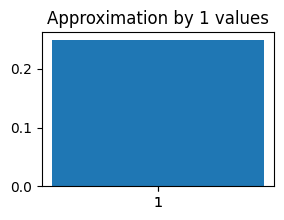

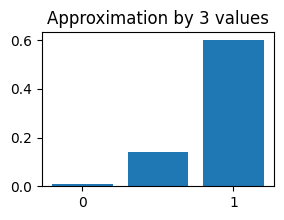

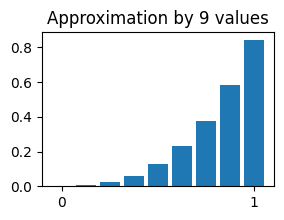

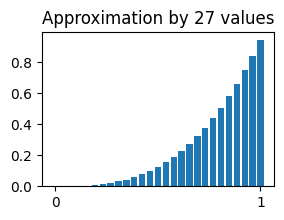

In [ ]:
##### Output the qmap itself #####

for layer in qmap.values:
    _N = len(layer)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(np.arange(_N),layer)

    ax.set_title(f'Approximation by {_N} values')
    ax.set_xticks([0, _N-1])
    ax.set_xticklabels(['0', '1'])

    plt.show()

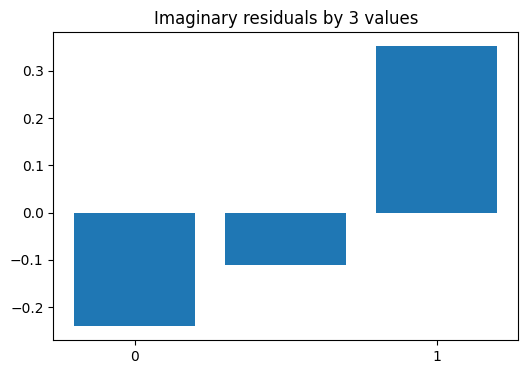

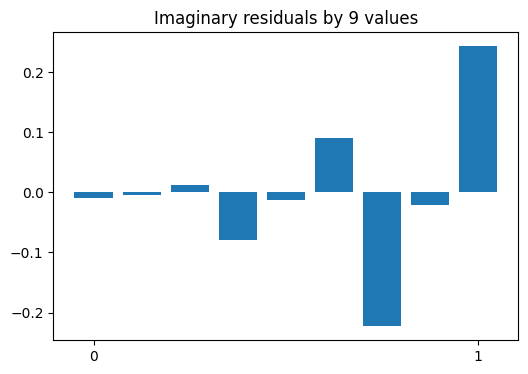

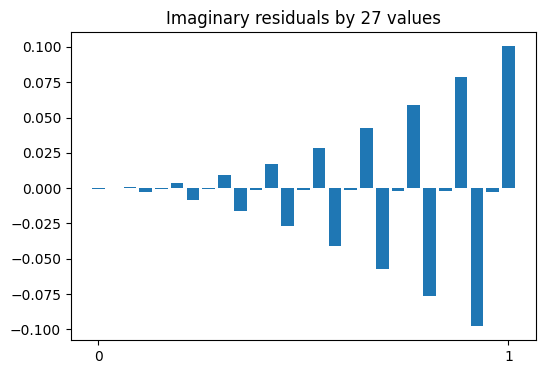

In [4]:
# Layerwise imaginary residuals of decomposition

for layer in qdecomp.contributions:
    _N = len(layer)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(np.arange(_N), np.real(layer))

    ax.set_title(f'Imaginary residuals by {_N} values')
    ax.set_xticks([0, _N-1])
    ax.set_xticklabels(['0', '1'])

    plt.show()

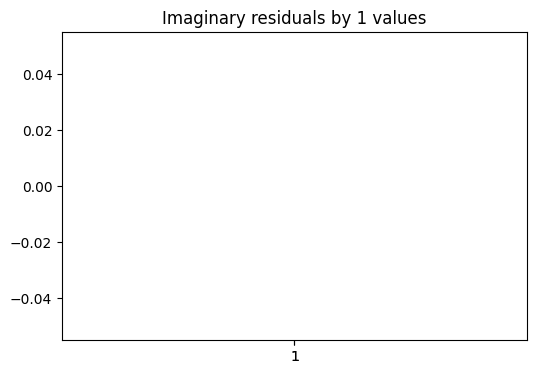

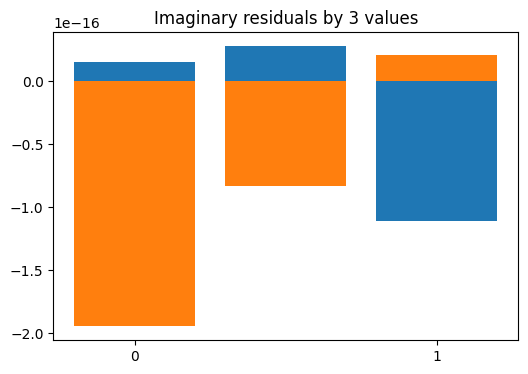

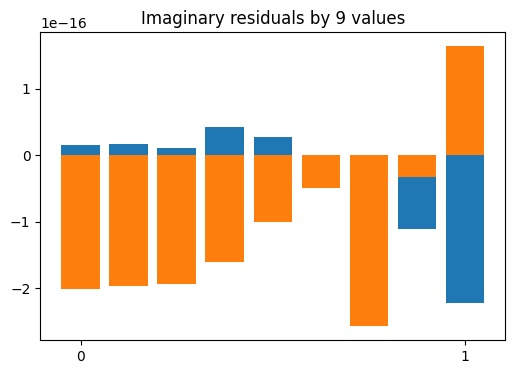

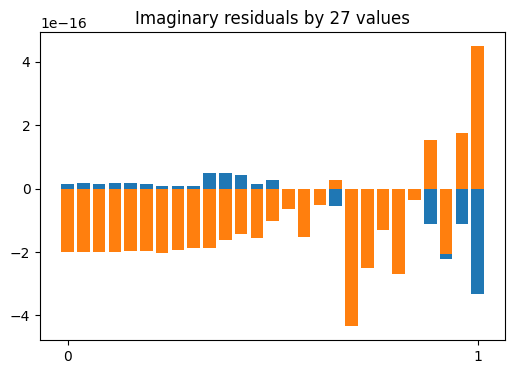

In [ ]:
for a,b in zip(qmap.values, qrecomp.values):
    assert len(a) == len(b)

    _N = len(a)
    diff = np.array(a) - np.array(b)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(np.arange(_N), np.real(diff))
    ax.bar(np.arange(_N), np.imag(diff))

    ax.set_title(f'Real and imaginary residuals by {_N} values')
    ax.set_xticks([0, _N-1])
    ax.set_xticklabels(['0', '1'])

    plt.show()